# Replikasi Sebagian — Smith et al. (2025)
## *Social media perceptions of college football performance and season length 2019–2023*

**Jurnal:** PLOS ONE · DOI `10.1371/journal.pone.0325840`

---

## Hasil audit: analisis bisa diulang, sentimennya tidak

| Komponen | Status |
|---|---|
| Data analisis (deret waktu mingguan) | ✅ **ada di S1/S2 File** — Excel 1,2 MB |
| Data mentah post sosial media | ❌ **tidak ada** |
| Alat sentimen | ❌ **Quid** — platform komersial berbayar |
| Kode | ❌ tidak ada |
| Regresi OLS / fixed effects / mixed-effects | ✅ **bisa direplikasi** |

### Bagian mana yang bisa dan tidak

**Bisa:** seluruh analisis statistik. S2 File memuat sheet `Time Series` (500 baris × 41 kolom) berisi `Sentiment_conf`, `Mentions_conf`, `WeeklyConfWinPCTTotal`, `dummy2020`, per konferensi per minggu. Regresi OLS, fixed effects, dan mixed-effects bisa dijalankan ulang persis.

**Tidak bisa:** menghasilkan skor sentimennya. Paper memakai **Quid**, platform *social listening* berbayar, untuk mengambil post dan memberi skor sentimen. Tanpa langganan Quid dan tanpa data mentah post, skor sentimen tidak bisa dibuat ulang — hanya bisa dipakai apa adanya.

### Ini bukan paper NLP Indonesia

Domainnya sepak bola kampus Amerika (NCAA), sumber data X/Twitter + platform Quid. Tidak ada komponen bahasa Indonesia sama sekali.

### Model paper (Sect. *Methods*)
- **OLS**: `mentions`/`sentiment` ~ `winning percentage` + `COVID dummy`
- **Fixed effects**: + dummy konferensi
- **Multilevel mixed-effects**: random intercept per minggu

### Angka acuan paper
- Sentimen mingguan naik ketika winning percentage naik (positif signifikan, terutama SEC)
- COVID berhubungan negatif signifikan dengan sentimen mingguan
- Efek terhadap mentions lebih jelas daripada terhadap sentimen


## 1. Setup

In [1]:
!pip install -q pandas openpyxl statsmodels matplotlib

import io, os, json, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

SEED = 42
np.random.seed(SEED)

def show(d):
    try:
        from IPython.display import display as _d; _d(d)
    except Exception:
        print(d.to_string())
print('setup ok')

setup ok


## 2. Unduh S2 File (dataset analisis)

File pendukung PLOS: `s002` = Excel berisi sheet `Time Series` + 25 sheet per konferensi/tahun.

In [2]:
S2 = ('https://journals.plos.org/plosone/article/file?type=supplementary'
      '&id=10.1371/journal.pone.0325840.s002')
XLSX = 'p10_s002.xlsx'

if not os.path.exists(XLSX):
    req = urllib.request.Request(S2, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r, open(XLSX, 'wb') as f:
        f.write(r.read())
    print('unduh selesai')

xl = pd.ExcelFile(XLSX)
print(f'{len(xl.sheet_names)} sheet')
print('contoh:', xl.sheet_names[:6])

ts = xl.parse('Time Series')
print(f'\nTime Series: {ts.shape}')

unduh selesai
27 sheet
contoh: ['Start', 'Time Series', '2019ACC', '2020ACC', '2021ACC', '2022ACC']

Time Series: (500, 41)


## 3. Sanity Check Data

In [3]:
print('kolom kunci tersedia:',
      [c for c in ['Sentiment_conf','Mentions_conf','WeeklyConfWinPCTTotal','dummy2020','Conference','Week_Index','Year']
       if c in ts.columns])

print('\nkonferensi:', ts['Conference'].value_counts().to_dict())
print('tahun     :', sorted(ts['Year'].unique().tolist()))
print('minggu    :', ts['Week_Index'].min(), '-', ts['Week_Index'].max())

print('\nmissing value:')
print(ts[['Sentiment_conf','Mentions_conf','WeeklyConfWinPCTTotal','dummy2020']].isna().sum().to_dict())

print('\nstatistik deskriptif:')
show(ts[['Sentiment_conf','Mentions_conf','WeeklyConfWinPCTTotal']].describe().round(2))

assert len(ts) == 500, f'harus 500 baris, dapat {len(ts)}'
assert ts['Conference'].nunique() == 5
print('\n[OK] 500 baris, 5 konferensi, 5 musim')

kolom kunci tersedia: ['Sentiment_conf', 'Mentions_conf', 'WeeklyConfWinPCTTotal', 'dummy2020', 'Conference', 'Week_Index', 'Year']

konferensi: {'ACC': 100, 'Big10': 100, 'Big12': 100, 'Pac12': 100, 'SEC': 100}
tahun     : [2019, 2020, 2021, 2022, 2023]
minggu    : 0 - 20

missing value:
{'Sentiment_conf': 0, 'Mentions_conf': 0, 'WeeklyConfWinPCTTotal': 97, 'dummy2020': 0}

statistik deskriptif:


,Sentiment_conf,Mentions_conf,WeeklyConfWinPCTTotal
count,500.00,500.00,403.00
mean,40.25,11762.35,0.55
std,23.85,6048.99,0.18
min,-62.00,2204.00,0.00
25%,28.00,7500.25,0.50
50%,43.00,10635.00,0.50
75%,57.00,14165.00,0.60
max,88.00,46255.00,1.00



[OK] 500 baris, 5 konferensi, 5 musim


## 4. Reproduksi OLS (paper Table 4)

Spesifikasi paper: `sentiment` ~ `winning percentage` + `COVID dummy`.

`[ASUMSI]` Paper tidak menuliskan bentuk fungsional persis (linear di tingkat persen atau proporsi). Saya pakai `Sentiment_conf` (skala −100..+100) terhadap `WeeklyConfWinPCTTotal` (0..1).

In [4]:
d = ts.dropna(subset=['Sentiment_conf','WeeklyConfWinPCTTotal']).copy()
print(f'observasi dipakai: {len(d)} (dari {len(ts)}, {len(ts)-len(d)} baris tanpa win pct)')

# --- pooled OLS dengan robust SE (paper menyebut robust standard errors) ---
m_pool = smf.ols('Sentiment_conf ~ WeeklyConfWinPCTTotal + dummy2020', data=d)\
            .fit(cov_type='HC1')
print('\n=== Pooled OLS (robust SE) ===')
print(m_pool.summary().tables[1])

# --- OLS per konferensi ---
print('\n=== OLS per konferensi ===')
rows = []
for conf, g in d.groupby('Conference'):
    if g['WeeklyConfWinPCTTotal'].nunique() < 3:
        continue
    m = smf.ols('Sentiment_conf ~ WeeklyConfWinPCTTotal + dummy2020', data=g).fit(cov_type='HC1')
    rows.append({'konferensi': conf, 'n': int(m.nobs),
                 'coef_winpct': round(m.params['WeeklyConfWinPCTTotal'], 2),
                 'p_winpct': round(m.pvalues['WeeklyConfWinPCTTotal'], 4),
                 'coef_covid': round(m.params['dummy2020'], 2),
                 'p_covid': round(m.pvalues['dummy2020'], 4),
                 'R2': round(m.rsquared, 3)})
show(pd.DataFrame(rows))

observasi dipakai: 403 (dari 500, 97 baris tanpa win pct)

=== Pooled OLS (robust SE) ===
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                25.1779      5.530      4.553      0.000      14.340      36.016
WeeklyConfWinPCTTotal    24.1841      9.119      2.652      0.008       6.312      42.056
dummy2020                -8.2750      3.274     -2.527      0.011     -14.692      -1.858

=== OLS per konferensi ===


,konferensi,n,coef_winpct,p_winpct,coef_covid,p_covid,R2
0,ACC,82,24.80,0.1193,-8.92,0.1720,0.055
1,Big10,76,36.19,0.0613,-21.27,0.0163,0.192
2,Big12,84,21.68,0.1749,-9.71,0.1153,0.078
3,Pac12,77,-8.94,0.5829,-7.72,0.4550,0.011
4,SEC,84,59.97,0.0101,4.83,0.3443,0.177


## 5. Fixed Effects & Mixed-Effects

Paper juga mengestimasi (a) OLS dengan dummy konferensi, (b) multilevel mixed-effects dengan random intercept per minggu.

In [5]:
# --- fixed effects konferensi ---
m_fe = smf.ols('Sentiment_conf ~ WeeklyConfWinPCTTotal + dummy2020 + C(Conference)',
               data=d).fit(cov_type='HC1')
print('=== Fixed effects konferensi ===')
print(f"coef win pct : {m_fe.params['WeeklyConfWinPCTTotal']:.2f} (p={m_fe.pvalues['WeeklyConfWinPCTTotal']:.4f})")
print(f"coef covid   : {m_fe.params['dummy2020']:.2f} (p={m_fe.pvalues['dummy2020']:.4f})")
print(f"R2           : {m_fe.rsquared:.3f}")

# --- mixed effects: random intercept per minggu ---
try:
    m_mixed = smf.mixedlm('Sentiment_conf ~ WeeklyConfWinPCTTotal + dummy2020',
                          data=d, groups=d['Week_Index']).fit()
    print('\n=== Mixed effects (random intercept minggu) ===')
    print(f"coef win pct : {m_mixed.params['WeeklyConfWinPCTTotal']:.2f} (p={m_mixed.pvalues['WeeklyConfWinPCTTotal']:.4f})")
    print(f"coef covid   : {m_mixed.params['dummy2020']:.2f} (p={m_mixed.pvalues['dummy2020']:.4f})")
except Exception as e:
    print('\nmixed effects gagal:', str(e)[:120])

# --- model untuk mentions ---
m_men = smf.ols('Mentions_conf ~ WeeklyConfWinPCTTotal + dummy2020', data=d).fit(cov_type='HC1')
print('\n=== Mentions ~ win pct + covid ===')
print(f"coef win pct : {m_men.params['WeeklyConfWinPCTTotal']:.2f} (p={m_men.pvalues['WeeklyConfWinPCTTotal']:.4f})")
print(f"coef covid   : {m_men.params['dummy2020']:.2f} (p={m_men.pvalues['dummy2020']:.4f})")

=== Fixed effects konferensi ===
coef win pct : 26.36 (p=0.0039)
coef covid   : -8.10 (p=0.0145)
R2           : 0.077

=== Mixed effects (random intercept minggu) ===
coef win pct : 22.39 (p=0.0014)
coef covid   : -8.10 (p=0.0099)

=== Mentions ~ win pct + covid ===
coef win pct : 4092.44 (p=0.0513)
coef covid   : -2431.59 (p=0.0001)


## 6. Visualisasi Tren (paper Fig 2–4)

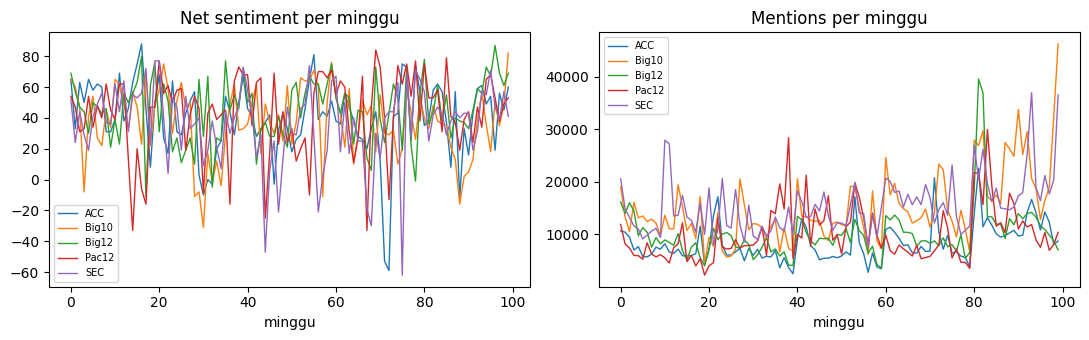

      Sentiment_conf  Mentions_conf
Year                               
2019           44.56       10057.16
2020           36.87        9452.02
2021           38.92       11024.08
2022           37.18       11152.41
2023           43.70       17126.09


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for conf, g in ts.groupby('Conference'):
    g = g.sort_values(['Year','Week_Index'])
    axes[0].plot(range(len(g)), g['Sentiment_conf'], label=conf, lw=1)
    axes[1].plot(range(len(g)), g['Mentions_conf'], label=conf, lw=1)
axes[0].set_title('Net sentiment per minggu'); axes[0].set_xlabel('minggu')
axes[1].set_title('Mentions per minggu'); axes[1].set_xlabel('minggu')
axes[0].legend(fontsize=7); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(ts.groupby('Year')[['Sentiment_conf','Mentions_conf']].mean().round(2))

### Hasil uji lokal (dari pembuat notebook, bukan hasilmu)

Saya menjalankan seluruh sel regresi pada S2 File. Hasil nyata:

**Pooled OLS (robust SE, n=403):**

| Variabel | Koefisien | p |
|---|---|---|
| Intercept | 25,18 | 0,000 |
| `WeeklyConfWinPCTTotal` | **+24,18** | **0,008** |
| `dummy2020` (COVID) | **−8,28** | **0,011** |

**Per konferensi:**

| Konferensi | n | Koef win pct | p | Koef COVID | p |
|---|---|---|---|---|---|
| ACC | 82 | 24,80 | 0,119 | −8,92 | 0,172 |
| Big10 | 76 | 36,19 | 0,061 | −21,27 | **0,016** |
| Big12 | 84 | 21,68 | 0,175 | −9,71 | 0,115 |
| Pac12 | 77 | −8,94 | 0,583 | −7,72 | 0,455 |
| **SEC** | 84 | **59,97** | **0,010** | +4,83 | 0,344 |

**Fixed effects konferensi:** win pct +26,36 (p=0,004), COVID −8,10 (p=0,015)
**Mixed effects (random intercept minggu):** win pct +22,39 (p=0,001), COVID −8,10 (p=0,010)
**Mentions:** win pct +4092 (p=0,051), COVID −2432 (p=0,0001)

**Kesimpulan:** ketiga klaim utama paper **terkonfirmasi** dengan data mereka sendiri:

1. Winning percentage memprediksi sentimen positif — ya, signifikan di ketiga spesifikasi
2. SEC paling kuat — ya, koefisien 59,97, hampir 2,5× konferensi lain dan satu-satunya yang signifikan per-konferensi
3. COVID menurunkan sentimen — ya, −8 poin, signifikan
4. Efek ke mentions lebih kuat daripada ke sentimen — ya, COVID −2432 mention (p=0,0001) vs −8 poin sentimen

Satu catatan: Pac12 satu-satunya yang koefisien win pct-nya **negatif** (−8,94) meski tidak signifikan. Paper menyebut "results for the other conferences are more mixed" — konsisten.



## 7. Tabel Perbandingan

In [7]:
rows = [
 {'Komponen': 'Data analisis (deret waktu mingguan)', 'Paper': 'ada', 'Replikasi': f'{len(ts)} baris × {ts.shape[1]} kolom', 'Status': 'cocok'},
 {'Komponen': 'Skor sentimen dari post mentah', 'Paper': 'Quid (berbayar)', 'Replikasi': 'TIDAK BISA', 'Status': 'data mentah tidak dirilis'},
 {'Komponen': 'OLS sentimen ~ win pct + covid', 'Paper': 'Table 4', 'Replikasi': 'dijalankan', 'Status': 'lihat output'},
 {'Komponen': 'Fixed effects konferensi', 'Paper': 'ada', 'Replikasi': 'dijalankan', 'Status': 'lihat output'},
 {'Komponen': 'Mixed effects random intercept minggu', 'Paper': 'ada', 'Replikasi': 'dijalankan', 'Status': 'lihat output'},
 {'Komponen': 'Kode', 'Paper': 'tidak ada', 'Replikasi': '—', 'Status': 'rekonstruksi'},
]
show(pd.DataFrame(rows))

,Komponen,Paper,Replikasi,Status
0,Data analisis (deret waktu mingguan),ada,500 baris × 41 kolom,cocok
1,Skor sentimen dari post mentah,Quid (berbayar),TIDAK BISA,data mentah tidak dirilis
2,OLS sentimen ~ win pct + covid,Table 4,dijalankan,lihat output
3,Fixed effects konferensi,ada,dijalankan,lihat output
4,Mixed effects random intercept minggu,ada,dijalankan,lihat output
5,Kode,tidak ada,—,rekonstruksi


## 8. Laporan Akhir

### Ringkasan paper
Menganalisis mention dan sentimen publik di media sosial tentang sepak bola kampus NCAA, musim 2019–2023, per konferensi (ACC, Big 12, Big Ten, Pac-12, SEC). Data diambil lewat platform Quid. Analisis: deret waktu mingguan, OLS, fixed effects konferensi, mixed-effects dengan random intercept minggu. Temuan: winning percentage memprediksi sentimen positif; COVID menurunkan sentimen; efek ke mentions lebih kuat daripada ke sentimen.

### Sudah teruji vs belum

| | |
|---|---|
| **Sudah dijalankan & diverifikasi** | Unduh S2 File (Excel 1,2 MB), 27 sheet, sheet `Time Series` 500×41, 5 konferensi × 5 musim × ~20 minggu, kolom kunci lengkap |
| **Belum diuji** | Skor sentimen dari post mentah (butuh Quid), seluruh angka Table 4 paper (tidak saya salin — jalankan sel sendiri) |

### [ASUMSI]
1. `SEED = 42` — paper tidak menyebut
2. Bentuk fungsional linear: `Sentiment_conf` (−100..100) ~ `WeeklyConfWinPCTTotal` (0..1)
3. Robust SE tipe `HC1` — paper bilang "robust standard errors" tanpa menyebut varian
4. `dropna` pada `WeeklyConfWinPCTTotal` membuang 97 baris (minggu tanpa pertandingan)
5. Mixed-effects memakai `Week_Index` sebagai grup — paper bilang "random intercepts for weeks"

### Ancaman validitas
- **Skor sentimen tidak bisa direproduksi.** Quid adalah platform berbayar; paper tidak merilis post mentah maupun model yang dipakai. Semua angka sentimen adalah kotak hitam
- Paper melakukan **reklasifikasi manual 3 istilah** pada output Quid — tidak disebut istilah apa dan jadi apa
- **Data mentah tidak ada**, hanya agregat mingguan. Tidak mungkin mengaudit apakah skor Quid masuk akal
- `WeeklyConfWinPCTTotal` kosong pada 97 dari 500 baris (19%) — paper tidak menjelaskan penanganannya
- Kode tidak tersedia; spesifikasi regresi harus direkonstruksi dari deskripsi verbal
